# Proyek Analisis Data: Air Quality Dataset (Beijing Multi-Site, 12 Stasiun)
- **Nama:** Khansa Amani Rahmadini
- **Email:** khansaramadhini20@gmail.com
- **ID Dicoding:** DS296B6X0889

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren rata-rata bulanan PM2.5 di 12 stasiun Beijing dan pada musim/bulan apa rata-rata PM2.5 melampaui 75 µg/m³ selama Maret 2013 – Februari 2017, sehingga periode peringatan dini dapat ditetapkan?
- **Pertanyaan 2:** Stasiun mana yang memiliki rata-rata PM2.5 tertinggi dan terendah, dan berapa persen hari per stasiun yang melampaui 75 µg/m³ selama Maret 2013 – Februari 2017, untuk menentukan prioritas lokasi intervensi?
- **Pertanyaan 3:** Seberapa besar selisih rata-rata PM2.5 harian saat kecepatan angin < 1 m/s dibandingkan > 3 m/s, dan arah angin apa yang paling dominan pada hari ber-PM2.5 > 150 µg/m³ selama Maret 2013 – Februari 2017, agar kondisi cuaca pemicu polusi dapat diantisipasi?

_Catatan: ambang 75 µg/m³ adalah batas rata-rata 24 jam PM2.5 Grade II standar kualitas udara China (GB 3095-2012). Setiap pertanyaan memenuhi unsur SMART: spesifik (PM2.5 & lokasi/faktor tertentu), terukur (µg/m³, persentase hari), berorientasi aksi (jadwal peringatan dini, prioritas lokasi, pemicu cuaca), relevan (kualitas udara kota), dan terikat waktu (Mar 2013 – Feb 2017)._

## Import Semua Packages/Library yang Digunakan

In [ ]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings
warnings.filterwarnings('ignore')

# --- gaya visual yang konsisten: warna tenang, satu warna aksen untuk sorotan ---
BLUE, LIGHT, ACCENT, GRAY = '#2F5D8A', '#A9C1D9', '#C8502E', '#6B7280'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9CA3AF', 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': '#E5E7EB', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.labelcolor': '#374151',
    'xtick.color': '#374151', 'ytick.color': '#374151'})
THRESH = 75   # ambang PM2.5 24 jam (µg/m3), standar China Grade II

## Data Wrangling

### Gathering Data

#### Load df 12 stasiun (satu berkas CSV per stasiun)

In [ ]:
files = sorted(glob.glob('data/PRSA_Data_*.csv'))
print(len(files), 'berkas ditemukan')
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print(df.shape)
df.head()

12 berkas ditemukan


(420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:**
- Data gabungan berisi **420.768 baris × 18 kolom** (12 stasiun × 35.064 jam); setiap stasiun memiliki jumlah baris yang sama.
- Kolom: waktu (`year, month, day, hour`), polutan (`PM2.5, PM10, SO2, NO2, CO, O3`), meteorologi (`TEMP, PRES, DEWP, RAIN, wd, WSPM`) dan `station`.

### Assessing Data

#### Identifying missing value, duplicate data, inconsistent value, and outlier problem

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  str    
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 62.1 MB


In [ ]:
# 1) Missing value
mv = pd.DataFrame({'jumlah': df.isna().sum(), 'persen': (df.isna().mean()*100).round(2)})
mv[mv.jumlah > 0].sort_values('jumlah', ascending=False)

,jumlah,persen
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


In [ ]:
# 2) Duplikat
print('Baris duplikat:', df.duplicated().sum())
print('Duplikat (station, waktu):', df.duplicated(subset=['station','year','month','day','hour']).sum())

# 3) Nilai tidak konsisten: PM2.5 adalah bagian dari PM10, sehingga PM2.5 tidak boleh > PM10
bad = df['PM2.5'] > df['PM10']
print(f"PM2.5 > PM10: {bad.sum():,} baris ({bad.mean()*100:.1f}%)")

# 4) Nilai ekstrem / sensor cap
print('PM2.5 >= 900 :', (df['PM2.5'] >= 900).sum(), 'baris | PM10 >= 900 :', (df['PM10'] >= 900).sum(), 'baris')

Baris duplikat: 0
Duplikat (station, waktu): 0
PM2.5 > PM10: 21,312 baris (5.1%)
PM2.5 >= 900 : 3 baris | PM10 >= 900 : 55 baris


In [ ]:
# 5) Outlier (aturan IQR) pada kolom numerik utama
rows = []
for c in ['PM2.5','PM10','SO2','NO2','CO','O3','WSPM']:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    rows.append((c, int((df[c] > q3 + 1.5*iqr).sum()), round(df[c].max(), 1)))
pd.DataFrame(rows, columns=['kolom','jumlah_outlier_atas','nilai_maks']).set_index('kolom')

,jumlah_outlier_atas,nilai_maks
kolom,,
PM2.5,19142,999.0
PM10,14658,999.0
SO2,35566,500.0
NO2,7021,290.0
CO,28054,10000.0
O3,16599,1071.0
WSPM,23079,13.2


In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
No,420768.0,17532.50,10122.12,1.00,8766.75,17532.5,26298.25,35064.0
year,420768.0,2014.66,1.18,2013.00,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.52,3.45,1.00,4.00,7.0,10.00,12.0
day,420768.0,15.73,8.80,1.00,8.00,16.0,23.00,31.0
hour,420768.0,11.50,6.92,0.00,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.79,80.82,2.00,20.00,55.0,111.00,999.0
PM10,414319.0,104.60,91.77,2.00,36.00,82.0,145.00,999.0
SO2,411747.0,15.83,21.65,0.29,3.00,7.0,20.00,500.0
NO2,408652.0,50.64,35.13,1.03,23.00,43.0,71.00,290.0
CO,400067.0,1230.77,1160.18,100.00,500.00,900.0,1500.00,10000.0


**Steps to Take:**
- *Missing value* → isi dengan interpolasi berbasis waktu per stasiun (maks. 6 jam untuk polutan, 24 jam untuk meteorologi); `wd` diisi nilai terdekat. Celah panjang tidak diisi agar tidak mengarang data.
- *Inconsistent value* (PM2.5 > PM10, mustahil secara fisik) → naikkan PM10 sama dengan PM2.5 pada baris tersebut; PM2.5 sebagai variabel utama tidak diubah.
- *Outlier* (nilai ≥ 900, batas atas sensor, dan lonjakan episode *smog*) → tidak dihapus karena bagian dari pertanyaan bisnis; analisis memakai rata-rata **harian** dan persentase hari melampaui ambang agar tahan terhadap lonjakan sesaat.
- *Duplicate data* → tidak ditemukan. Kolom waktu terpisah digabung menjadi `datetime`, kolom `No` dibuang.

**Insight:**
- *Missing value* terbanyak pada CO (≈4,9%), O3 (≈3,2%), NO2 (≈2,9%), SO2 (≈2,1%) dan PM2.5 (≈2,1%); `wd` ≈0,4%; kolom meteorologi < 0,1%.
- Sekitar 21 ribu baris (≈5%) memiliki PM2.5 > PM10.
- Tidak ada baris duplikat.

### Cleaning Data

#### Fixing inconsistent value and missing value problem

In [ ]:
# 1) Buat kolom datetime, urutkan, buang kolom 'No'
df['datetime'] = pd.to_datetime(df[['year','month','day','hour']])
df = df.drop(columns='No').sort_values(['station','datetime']).reset_index(drop=True)

# 2) Perbaiki ketidakkonsistenan PM2.5 > PM10  (PM10 harus >= PM2.5)
mask = df['PM2.5'] > df['PM10']
df.loc[mask, 'PM10'] = df.loc[mask, 'PM2.5']
print('Baris diperbaiki:', mask.sum())

# 3) Tangani missing value per stasiun
polutan = ['PM2.5','PM10','SO2','NO2','CO','O3']
meteo   = ['TEMP','PRES','DEWP','RAIN','WSPM']
before = df[polutan + meteo + ['wd']].isna().sum()

parts = []
for st, g in df.groupby('station'):
    g = g.set_index('datetime').copy()
    g[polutan] = g[polutan].interpolate(method='time', limit=6,  limit_area='inside')
    g[meteo]   = g[meteo].interpolate(method='time', limit=24, limit_area='inside')
    g['wd']    = g['wd'].ffill(limit=24).bfill(limit=24)
    parts.append(g.reset_index())
df = pd.concat(parts, ignore_index=True)

# Interpolasi dapat memunculkan kembali PM2.5 > PM10 -> terapkan ulang aturan konsistensi
mask = df['PM2.5'] > df['PM10']
df.loc[mask, 'PM10'] = df.loc[mask, 'PM2.5']

after = df[polutan + meteo + ['wd']].isna().sum()
pd.DataFrame({'sebelum': before, 'sesudah': after, 'terisi': before - after})

Baris diperbaiki: 21312


,sebelum,sesudah,terisi
PM2.5,8739,3354,5385
PM10,6449,2294,4155
SO2,9021,3896,5125
NO2,12116,5533,6583
CO,20701,11991,8710
O3,13277,5437,7840
TEMP,398,0,398
PRES,393,0,393
DEWP,403,0,403
RAIN,390,0,390


In [ ]:
# Verifikasi: tidak ada lagi PM2.5 > PM10, tidak ada duplikat, rentang waktu benar
print('PM2.5 > PM10 :', (df['PM2.5'] > df['PM10']).sum())
print('Duplikat      :', df.duplicated(subset=['station','datetime']).sum())
print('Rentang waktu :', df['datetime'].min(), '->', df['datetime'].max())

PM2.5 > PM10 : 0
Duplikat      : 0
Rentang waktu : 2013-03-01 00:00:00 -> 2017-02-28 23:00:00


#### Aggregating data harian per stasiun dan menyimpan `main_data.csv` untuk dashboard

In [ ]:
# Agregasi harian per stasiun (dasar seluruh analisis berikutnya).
# Nilai PM2.5 harian hanya dihitung bila minimal 18 dari 24 jam tersedia.
df['date'] = df['datetime'].dt.floor('D')
mode_wd = lambda s: s.mode().iat[0] if s.notna().any() else np.nan

daily = df.groupby(['station','date']).agg(
    PM25=('PM2.5','mean'), PM25_jam=('PM2.5','count'),
    PM10=('PM10','mean'), SO2=('SO2','mean'), NO2=('NO2','mean'),
    CO=('CO','mean'), O3=('O3','mean'), TEMP=('TEMP','mean'),
    PRES=('PRES','mean'), DEWP=('DEWP','mean'), RAIN=('RAIN','sum'),
    WSPM=('WSPM','mean'), wd=('wd', mode_wd)).reset_index()
daily.loc[daily['PM25_jam'] < 18, 'PM25'] = np.nan
daily = daily.drop(columns='PM25_jam')

daily['year']  = daily['date'].dt.year
daily['month'] = daily['date'].dt.month
SEASON = {12:'Dingin',1:'Dingin',2:'Dingin',3:'Semi',4:'Semi',5:'Semi',
          6:'Panas',7:'Panas',8:'Panas',9:'Gugur',10:'Gugur',11:'Gugur'}
SEASON_ORDER = ['Dingin','Semi','Panas','Gugur']
daily['season'] = daily['month'].map(SEASON)

print(daily.shape, '| hari PM2.5 kosong:', daily['PM25'].isna().sum())
daily.head()

(17532, 17) | hari PM2.5 kosong: 205


,station,date,PM25,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd,year,month,season
0,Aotizhongxin,2013-03-01,7.125000,10.750000,11.708333,22.583333,429.166667,63.875000,1.391667,1026.875000,-18.745833,0.0,3.254167,N,2013,3,Semi
1,Aotizhongxin,2013-03-02,30.750000,42.083333,36.625000,66.666667,824.916667,29.750000,0.616667,1026.850000,-15.937500,0.0,1.479167,NE,2013,3,Semi
2,Aotizhongxin,2013-03-03,76.916667,120.541667,61.291667,81.000000,1620.625000,19.125000,5.566667,1014.608333,-12.316667,0.0,1.658333,NNE,2013,3,Semi
3,Aotizhongxin,2013-03-04,22.708333,44.583333,22.854167,46.187500,606.250000,53.750000,9.962500,1017.650000,-11.683333,0.0,2.404167,N,2013,3,Semi
4,Aotizhongxin,2013-03-05,148.875000,183.791667,93.875000,132.833333,2357.958333,68.458333,6.291667,1010.900000,-7.525000,0.0,1.129167,NE,2013,3,Semi


In [ ]:
cols = ['station','date','year','month','season','PM25','PM10','SO2','NO2','CO','O3',
        'TEMP','PRES','DEWP','RAIN','WSPM','wd']
main = daily[cols].copy()
for c in ['PM25','PM10','SO2','NO2','CO','O3','TEMP','PRES','DEWP','RAIN','WSPM']:
    main[c] = main[c].round(2)
main.to_csv('dashboard/main_data.csv', index=False)
print(main.shape); main.head()

(17532, 17)


,station,date,year,month,season,PM25,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd
0,Aotizhongxin,2013-03-01,2013,3,Semi,7.12,10.75,11.71,22.58,429.17,63.88,1.39,1026.88,-18.75,0.0,3.25,N
1,Aotizhongxin,2013-03-02,2013,3,Semi,30.75,42.08,36.62,66.67,824.92,29.75,0.62,1026.85,-15.94,0.0,1.48,NE
2,Aotizhongxin,2013-03-03,2013,3,Semi,76.92,120.54,61.29,81.00,1620.62,19.12,5.57,1014.61,-12.32,0.0,1.66,NNE
3,Aotizhongxin,2013-03-04,2013,3,Semi,22.71,44.58,22.85,46.19,606.25,53.75,9.96,1017.65,-11.68,0.0,2.40,N
4,Aotizhongxin,2013-03-05,2013,3,Semi,148.88,183.79,93.88,132.83,2357.96,68.46,6.29,1010.90,-7.52,0.0,1.13,NE


**Insight:**
- Seluruh *missing value* berjarak pendek berhasil diisi; ketidakkonsistenan PM2.5 > PM10 menjadi nol; tidak ada duplikat.
- Data per jam diringkas menjadi **harian per stasiun** (17.532 baris), sesuai dengan ambang standar 24 jam dan lebih ringkas untuk dashboard.

## Exploratory Data Analysis (EDA)

### Explore Pertanyaan 1: tren bulanan dan pola musiman PM2.5

In [ ]:
daily['year_month'] = daily['date'].dt.to_period('M').dt.to_timestamp()
monthly = daily.groupby('year_month')['PM25'].mean()

print('Rata-rata PM2.5 seluruh periode: %.1f µg/m3' % daily['PM25'].mean())
print('Jumlah bulan (dari %d) dengan rata-rata > %d: %d' % (len(monthly), THRESH, (monthly > THRESH).sum()))
print('Bulan tertinggi :', monthly.idxmax().strftime('%b %Y'), round(monthly.max(), 1))
print('Bulan terendah  :', monthly.idxmin().strftime('%b %Y'), round(monthly.min(), 1))

season_tbl = daily.groupby('season')['PM25'].agg(rata2='mean', persen_hari_over=lambda s: (s > THRESH).mean()*100)
season_tbl = season_tbl.reindex(SEASON_ORDER).round(1)
display(season_tbl)

month_tbl = daily.groupby('month')['PM25'].mean().round(1)
display(month_tbl.to_frame('rata2_PM25').T)

# Tahun penuh saja (2014-2016) agar adil
yearly = daily[daily['year'].between(2014, 2016)].groupby('year')['PM25'].mean().round(1)
display(yearly.to_frame('rata2_PM25').T)

Rata-rata PM2.5 seluruh periode: 79.9 µg/m3
Jumlah bulan (dari 48) dengan rata-rata > 75: 23
Bulan tertinggi : Feb 2014 153.6
Bulan terendah  : Feb 2016 42.8


,rata2,persen_hari_over
season,,
Dingin,95.8,44.9
Semi,77.0,40.5
Panas,64.6,33.8
Gugur,82.2,40.4


month,1,2,3,4,5,6,7,8,9,10,11,12
rata2_PM25,93.5,89.0,94.7,72.9,63.1,69.0,71.7,53.5,61.4,91.6,93.3,104.5


year,2014,2015,2016
rata2_PM25,86.1,79.5,72.0


**Insight:**
- Rata-rata PM2.5 seluruh periode adalah **79,9 µg/m³**, sedikit di atas ambang 75 µg/m³. **23 dari 48 bulan (48%)** memiliki rata-rata di atas ambang.
- Pola musiman jelas: musim dingin tertinggi (**95,8 µg/m³**, 44,9% hari > 75) dan musim panas terendah (**64,6 µg/m³**, 33,8% hari > 75). Musim gugur (82,2) dan semi (77,0) juga berada di atas ambang.
- Per bulan kalender, rata-rata melampaui 75 µg/m³ pada **Oktober–Maret** (Des tertinggi 104,5; Okt 91,6; Nov 93,3; Jan 93,5; Feb 89,0; Mar 94,7), sedangkan April–September berada di bawah ambang (terendah Agustus 53,5).
- Bulan paling buruk adalah **Februari 2014 (153,6 µg/m³)**, sedangkan terbaik **Februari 2016 (42,8 µg/m³)**; variasi antar tahun pada bulan yang sama sangat besar.
- Pada tahun penuh, rata-rata turun dari **86,1 (2014) → 79,5 (2015) → 72,0 (2016)**, penurunan ±16%.

### Explore Pertanyaan 2: perbandingan PM2.5 antar stasiun

In [ ]:
station_tbl = daily.groupby('station')['PM25'].agg(
    rata2='mean',
    persen_hari_over75=lambda s: (s > THRESH).mean()*100,
    persen_hari_over150=lambda s: (s > 150).mean()*100).round(1)
station_tbl = station_tbl.sort_values('rata2', ascending=False)
station_tbl

,rata2,persen_hari_over75,persen_hari_over150
station,,,
Dongsi,86.2,42.8,14.2
Nongzhanguan,85.2,42.6,14.9
Wanshouxigong,84.9,42.2,13.8
Gucheng,83.8,42.4,12.9
Wanliu,83.4,42.7,13.1
Guanyuan,83.0,42.0,12.8
Aotizhongxin,82.9,41.6,12.9
Tiantan,82.1,41.1,13.1
Shunyi,79.8,40.5,13.0


In [ ]:
print('Selisih stasiun tertinggi vs terendah: %.1f µg/m3 (%.0f%%)' % (
    station_tbl.rata2.max() - station_tbl.rata2.min(),
    (station_tbl.rata2.max() / station_tbl.rata2.min() - 1) * 100))

Selisih stasiun tertinggi vs terendah: 20.4 µg/m3 (31%)


**Insight:**
- Stasiun tertinggi: **Dongsi (86,2 µg/m³)**, disusul Nongzhanguan (85,2) dan Wanshouxigong (84,9). Terendah: **Dingling (65,8 µg/m³)**, lalu Huairou (69,7) dan Changping (71,3).
- Selisih tertinggi–terendah **20,4 µg/m³ (±31%)**.
- Persentase hari melampaui 75 µg/m³ berkisar **31,1% (Dingling) hingga 42,8% (Dongsi)**; hari > 150 µg/m³ berkisar 9,1%–14,9%.
- Seluruh stasiun, termasuk yang terbersih, memiliki rata-rata > 65 µg/m³ dan lebih dari 31% harinya melampaui ambang, sehingga masalahnya bersifat regional, bukan hanya lokal.

### Explore Pertanyaan 3: pengaruh kecepatan dan arah angin terhadap PM2.5

In [ ]:
w = daily.dropna(subset=['PM25','WSPM']).copy()
w['kelas_angin'] = pd.cut(w['WSPM'], bins=[0, 1, 2, 3, np.inf], right=False,
                          labels=['< 1 m/s','1–2 m/s','2–3 m/s','> 3 m/s'])
wind_tbl = w.groupby('kelas_angin', observed=True).agg(
    jumlah_hari=('PM25','size'), rata2_PM25=('PM25','mean'),
    persen_over75=('PM25', lambda s: (s > THRESH).mean()*100)).round(1)
display(wind_tbl)

lo, hi = wind_tbl.loc['< 1 m/s','rata2_PM25'], wind_tbl.loc['> 3 m/s','rata2_PM25']
print('Selisih: %.1f µg/m3 -> PM2.5 %.0f%% lebih rendah saat angin > 3 m/s' % (lo-hi, (1-hi/lo)*100))
print('Korelasi Pearson PM2.5 vs WSPM: %.2f' % w['PM25'].corr(w['WSPM']))

,jumlah_hari,rata2_PM25,persen_over75
kelas_angin,,,
< 1 m/s,2130,127.2,65.5
1–2 m/s,10489,85.7,44.7
2–3 m/s,3424,50.9,23.4
> 3 m/s,1284,30.7,8.3


Selisih: 96.5 µg/m3 -> PM2.5 76% lebih rendah saat angin > 3 m/s
Korelasi Pearson PM2.5 vs WSPM: -0.38


In [ ]:
DIR16 = ['N','NNE','NE','ENE','E','ESE','SE','SSE','S','SSW','SW','WSW','W','WNW','NW','NNW']
d = daily.dropna(subset=['PM25','wd'])
heavy = d[d['PM25'] > 150]
share = pd.DataFrame({
    'semua_hari': d['wd'].value_counts(normalize=True)*100,
    'hari_PM25_>150': heavy['wd'].value_counts(normalize=True)*100}).reindex(DIR16).fillna(0).round(1)
print('Jumlah hari-stasiun dengan PM2.5 > 150:', len(heavy), '(%.1f%% dari seluruh hari)' % (len(heavy)/len(d)*100))
display(share.T)
print('Arah dominan pada hari PM2.5 > 150:', share['hari_PM25_>150'].nlargest(3).to_dict())
# Rata-rata PM2.5 menurut arah angin
display(d.groupby('wd')['PM25'].mean().reindex(DIR16).round(1).to_frame('rata2_PM25').T)

Jumlah hari-stasiun dengan PM2.5 > 150: 2194 (12.7% dari seluruh hari)


wd,N,NNE,NE,ENE,E,ESE,SE,SSE,S,SSW,SW,WSW,W,WNW,NW,NNW
semua_hari,9.0,5.3,13.3,9.8,8.9,5.8,2.7,2.6,3.2,4.7,7.8,2.9,2.6,5.4,9.8,6.4
hari_PM25_>150,7.4,4.3,15.3,18.8,13.9,7.5,3.2,1.9,2.4,3.0,3.8,2.3,2.1,3.6,5.2,5.4


Arah dominan pada hari PM2.5 > 150: {'ENE': 18.8, 'NE': 15.3, 'E': 13.9}


wd,N,NNE,NE,ENE,E,ESE,SE,SSE,S,SSW,SW,WSW,W,WNW,NW,NNW
rata2_PM25,66.6,65.4,84.7,106.0,108.1,99.9,94.8,87.7,87.8,80.3,74.2,71.6,70.1,59.7,52.4,63.1


**Insight:**
- Kecepatan angin berkaitan kuat dengan PM2.5 (korelasi **−0,38**). Rata-rata PM2.5 turun bertahap: **127,2 (< 1 m/s) → 85,7 → 50,9 → 30,7 µg/m³ (> 3 m/s)**.
- Selisih angin lemah vs kencang adalah **96,5 µg/m³ (PM2.5 76% lebih rendah)**; pada angin < 1 m/s, **65,5%** harinya melampaui 75 µg/m³, sedangkan pada angin > 3 m/s hanya **8,3%**.
- Dari 2.194 hari-stasiun dengan PM2.5 > 150 µg/m³ (12,7% dari seluruh hari), arah angin dominan adalah **ENE (18,8%)**, **NE (15,3%)**, dan **E (13,9%)**; ketiganya mencakup ±48% hari polusi berat, padahal hanya ±32% dari seluruh hari. Angin dari NW/WNW/NNW (arah bersih) hampir tidak ada pada hari polusi berat.
- Rata-rata PM2.5 tertinggi terjadi pada angin E (108,1) dan ENE (106,0), terendah pada NW (52,4).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Tren bulanan dan pola musiman PM2.5

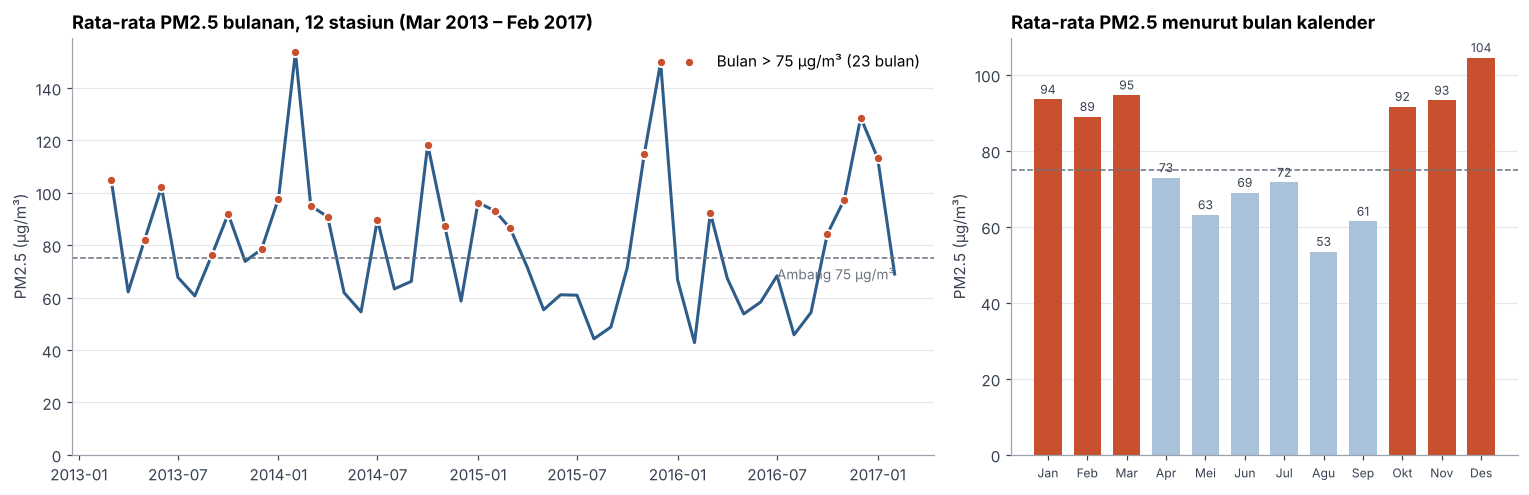

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.7, 1]})

# (a) tren bulanan
ax = axes[0]
ax.plot(monthly.index, monthly.values, color=BLUE, lw=2, zorder=2)
over = monthly[monthly > THRESH]
ax.scatter(over.index, over.values, color=ACCENT, s=36, zorder=3, edgecolor='white', linewidth=1.2,
           label=f'Bulan > {THRESH} µg/m³ ({len(over)} bulan)')
ax.axhline(THRESH, color=GRAY, ls='--', lw=1)
ax.text(monthly.index[-1], THRESH - 8, 'Ambang 75 µg/m³', color=GRAY, fontsize=9, ha='right')
ax.set_title('Rata-rata PM2.5 bulanan, 12 stasiun (Mar 2013 – Feb 2017)')
ax.set_ylabel('PM2.5 (µg/m³)'); ax.set_ylim(0)
ax.legend(frameon=False, loc='upper right')

# (b) rata-rata menurut bulan kalender
ax = axes[1]
nama = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']
vals = daily.groupby('month')['PM25'].mean()
cols = [ACCENT if v > THRESH else LIGHT for v in vals.values]
bars = ax.bar(nama, vals.values, color=cols, width=0.7)
ax.axhline(THRESH, color=GRAY, ls='--', lw=1)
ax.set_title('Rata-rata PM2.5 menurut bulan kalender')
ax.set_ylabel('PM2.5 (µg/m³)')
for b, v in zip(bars, vals.values):
    ax.text(b.get_x()+b.get_width()/2, v+1.5, f'{v:.0f}', ha='center', fontsize=8, color='#374151')
ax.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()

### Pertanyaan 2: Perbandingan PM2.5 antar stasiun

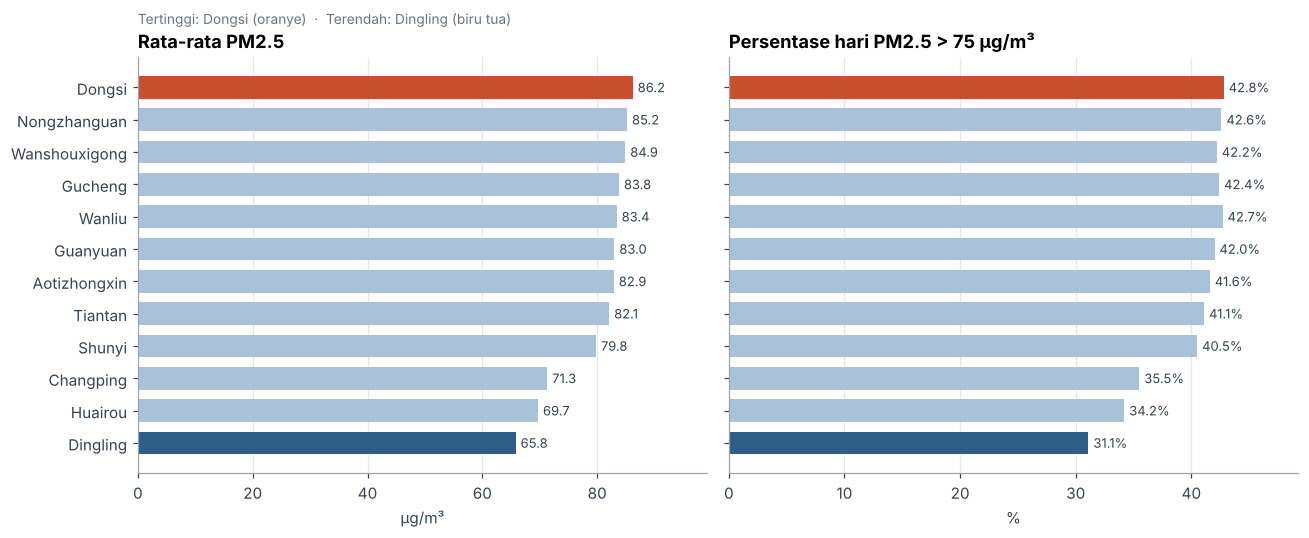

In [ ]:
st = station_tbl.sort_values('rata2')           # terendah di bawah -> tertinggi di atas
top, low = st.rata2.idxmax(), st.rata2.idxmin()
colors = [ACCENT if s == top else BLUE if s == low else LIGHT for s in st.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, col, ttl, unit in [(axes[0], 'rata2', 'Rata-rata PM2.5', 'µg/m³'),
                           (axes[1], 'persen_hari_over75', f'Persentase hari PM2.5 > {THRESH} µg/m³', '%')]:
    ax.barh(st.index, st[col], color=colors, height=0.7)
    ax.set_title(ttl); ax.grid(axis='y', visible=False); ax.grid(axis='x')
    for y, v in enumerate(st[col]):
        ax.text(v + st[col].max()*0.01, y, f'{v:.1f}' + ('%' if unit == '%' else ''), va='center', fontsize=8.5, color='#374151')
    ax.set_xlim(0, st[col].max()*1.15); ax.set_xlabel(unit)
axes[0].text(0, 1.08, f'Tertinggi: {top} (oranye)  ·  Terendah: {low} (biru tua)', transform=axes[0].transAxes, fontsize=9, color=GRAY)
plt.tight_layout(); plt.show()

### Pertanyaan 3: Kecepatan dan arah angin

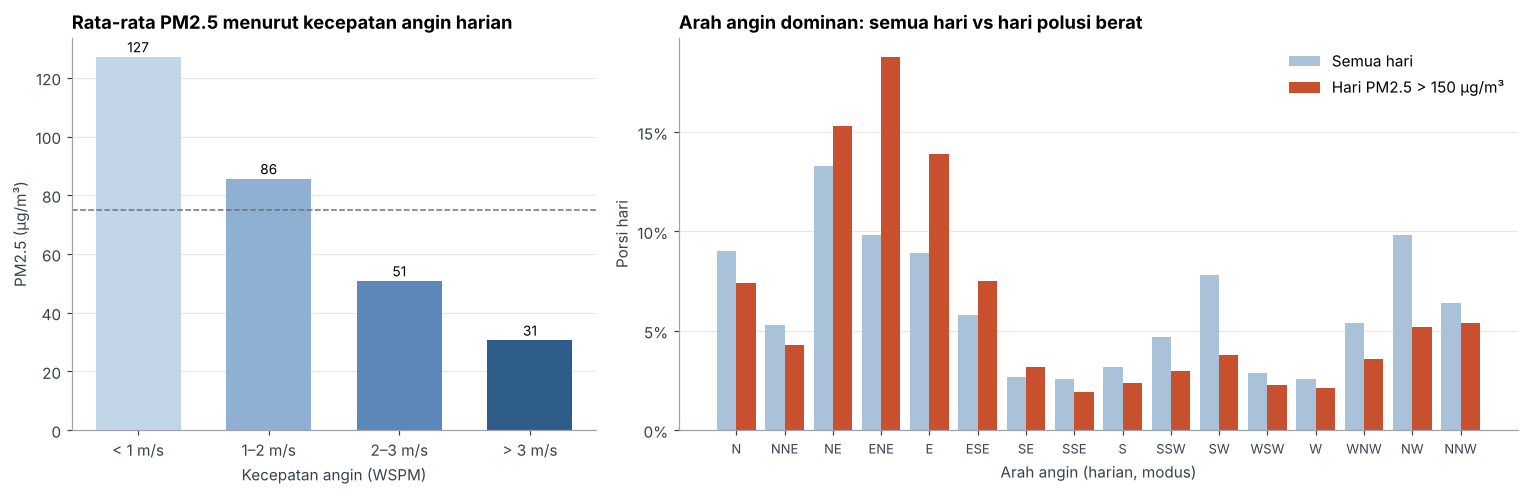

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1.6]})

ax = axes[0]
ramp = ['#C3D5E8', '#8FB0D2', '#5B88B8', '#2F5D8A']
bars = ax.bar(wind_tbl.index.astype(str), wind_tbl['rata2_PM25'], color=ramp, width=0.65)
for b, v in zip(bars, wind_tbl['rata2_PM25']):
    ax.text(b.get_x()+b.get_width()/2, v+1.5, f'{v:.0f}', ha='center', fontsize=9)
ax.axhline(THRESH, color=GRAY, ls='--', lw=1)
ax.set_title('Rata-rata PM2.5 menurut kecepatan angin harian')
ax.set_xlabel('Kecepatan angin (WSPM)'); ax.set_ylabel('PM2.5 (µg/m³)')

ax = axes[1]
x = np.arange(len(DIR16)); wd_w = 0.4
ax.bar(x - wd_w/2, share['semua_hari'], wd_w, color=LIGHT, label='Semua hari')
ax.bar(x + wd_w/2, share['hari_PM25_>150'], wd_w, color=ACCENT, label='Hari PM2.5 > 150 µg/m³')
ax.set_xticks(x); ax.set_xticklabels(DIR16, fontsize=8.5)
ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title('Arah angin dominan: semua hari vs hari polusi berat')
ax.set_xlabel('Arah angin (harian, modus)'); ax.set_ylabel('Porsi hari')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Insight:**
- **Pertanyaan 1:** titik oranye (bulan di atas 75 µg/m³) berulang pada musim dingin/akhir hingga awal tahun, dengan puncak Februari 2014; bar bulan kalender menegaskan **Oktober–Maret** sebagai jendela risiko, sedangkan April–September relatif lebih bersih. Tren tahunan membaik, tetapi pola musiman bertahan.
- **Pertanyaan 2:** stasiun pusat kota (Dongsi, Nongzhanguan, Wanshouxigong) berada di puncak, sedangkan stasiun utara/pinggiran (Dingling, Huairou, Changping) paling rendah. Urutan rata-rata dan persentase hari > 75 sangat mirip, sehingga peringkat stabil. Sumbu dimulai dari nol agar selisih (±31%) tidak terlihat berlebihan.
- **Pertanyaan 3:** semakin kencang angin, semakin rendah PM2.5 (127 → 31 µg/m³); hari polusi berat (> 150 µg/m³) didominasi angin dari sektor timur–timur laut (NE, ENE, E), sedangkan angin dari barat laut jarang terjadi saat polusi berat.

## Analisis Lanjutan (Opsional)

**Manual Grouping (Binning) — kategori kualitas udara PM2.5.** Tujuan: mengelompokkan setiap hari-stasiun ke kategori kualitas udara berdasarkan aturan domain (batas AQI PM2.5 24 jam China: 0–35, 35–75, 75–115, 115–150, 150–250, > 250 µg/m³) memakai `pd.cut`, tanpa algoritma *machine learning*. Dengan kategori ini stakeholder dapat melihat bukan hanya rata-rata, tetapi **seberapa sering** udara berada pada level berbahaya.

In [ ]:
AQI_BINS = [0, 35, 75, 115, 150, 250, np.inf]
AQI_LABELS = ['Sangat baik (0–35)', 'Baik (35–75)', 'Tercemar ringan (75–115)',
              'Tercemar sedang (115–150)', 'Tercemar berat (150–250)', 'Sangat berat (>250)']
daily['kategori'] = pd.cut(daily['PM25'], bins=AQI_BINS, labels=AQI_LABELS, include_lowest=True)

kat_all = daily['kategori'].value_counts(normalize=True).reindex(AQI_LABELS)*100
display(kat_all.round(1).to_frame('persen_hari').T)

full = daily[daily['year'].between(2014, 2016)]
kat_year = pd.crosstab(full['year'], full['kategori'], normalize='index').reindex(columns=AQI_LABELS)*100
display(kat_year.round(1))

kategori,Sangat baik (0–35),Baik (35–75),Tercemar ringan (75–115),Tercemar sedang (115–150),Tercemar berat (150–250),Sangat berat (>250)
persen_hari,29.6,30.1,18.2,9.5,9.2,3.4


kategori,Sangat baik (0–35),Baik (35–75),Tercemar ringan (75–115),Tercemar sedang (115–150),Tercemar berat (150–250),Sangat berat (>250)
year,,,,,,
2014,26.4,29.0,19.7,11.0,9.6,4.3
2015,31.1,30.1,16.7,9.6,8.7,3.8
2016,34.6,29.5,18.0,7.7,7.5,2.8


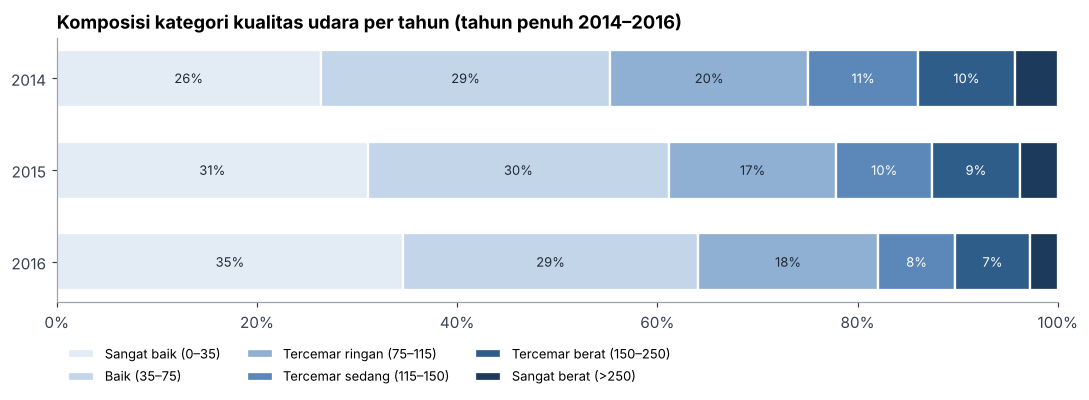

In [ ]:
RAMP6 = ['#E3ECF5', '#C3D5E8', '#8FB0D2', '#5B88B8', '#2F5D8A', '#1B3A5C']
fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(kat_year))
for lab, c in zip(AQI_LABELS, RAMP6):
    ax.barh(kat_year.index.astype(str), kat_year[lab], left=left, color=c, label=lab,
            edgecolor='white', linewidth=1.5, height=0.62)
    for y, (l, v) in enumerate(zip(left, kat_year[lab])):
        if v >= 6:
            ax.text(l + v/2, y, f'{v:.0f}%', ha='center', va='center', fontsize=8.5,
                    color='white' if lab in AQI_LABELS[3:] else '#1F2937')
    left += kat_year[lab].values
ax.invert_yaxis(); ax.grid(False); ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title('Komposisi kategori kualitas udara per tahun (tahun penuh 2014–2016)')
ax.legend(ncol=3, frameon=False, bbox_to_anchor=(0, -0.12), loc='upper left', fontsize=8.5)
plt.tight_layout(); plt.show()

**Geospatial Analysis — sebaran PM2.5 antar stasiun.** Tujuan: melihat apakah ada pola spasial (mis. pusat kota vs pinggiran/pegunungan). Dataset tidak menyertakan koordinat, sehingga koordinat berikut adalah **perkiraan lokasi distrik/stasiun** (bukan koordinat resmi sensor) dan hanya dipakai untuk visualisasi pola geografis.

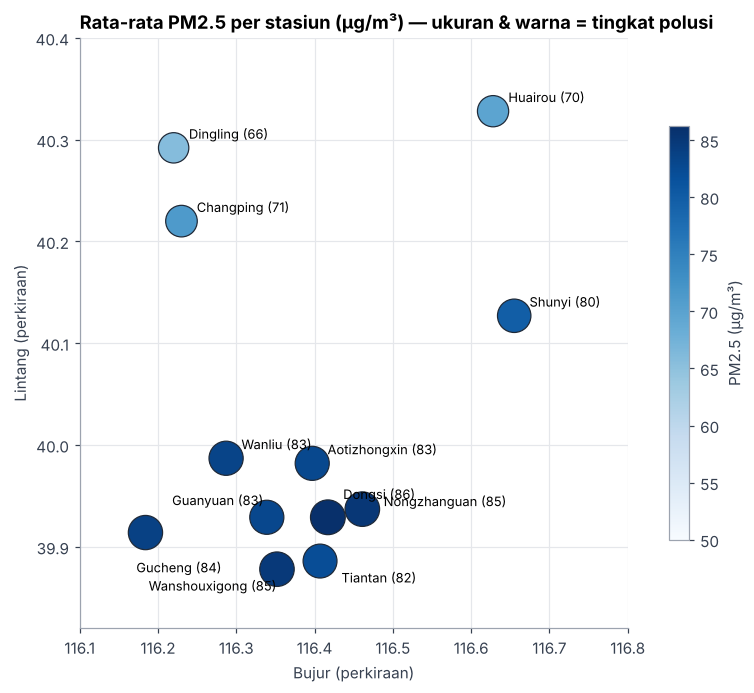

In [ ]:
COORD = {  # (lat, lon) perkiraan
 'Aotizhongxin': (39.982, 116.397), 'Changping': (40.220, 116.230), 'Dingling': (40.292, 116.220),
 'Dongsi': (39.929, 116.417), 'Guanyuan': (39.929, 116.339), 'Gucheng': (39.914, 116.184),
 'Huairou': (40.328, 116.628), 'Nongzhanguan': (39.937, 116.461), 'Shunyi': (40.127, 116.655),
 'Tiantan': (39.886, 116.407), 'Wanliu': (39.987, 116.287), 'Wanshouxigong': (39.878, 116.352)}
geo = station_tbl.join(pd.DataFrame(COORD, index=['lat','lon']).T)

fig, ax = plt.subplots(figsize=(8, 6.4))
sc = ax.scatter(geo.lon, geo.lat, c=geo.rata2, s=geo.rata2*6, cmap='Blues', vmin=50,
                edgecolor='#1F2937', linewidth=0.8, zorder=3)
OFF = {'Dongsi': (10, 12), 'Nongzhanguan': (14, 2), 'Guanyuan': (-62, 8), 'Tiantan': (14, -14),
       'Wanshouxigong': (-84, -14), 'Aotizhongxin': (10, 6), 'Gucheng': (-6, -26)}
for n, r in geo.iterrows():
    ax.annotate(f'{n} ({r.rata2:.0f})', (r.lon, r.lat), textcoords='offset points',
                xytext=OFF.get(n, (10, 6)), fontsize=8.5)
ax.grid(True, axis='both'); ax.set_aspect(1.3)
ax.set_xlim(116.1, 116.8); ax.set_ylim(39.82, 40.4)
ax.set_xlabel('Bujur (perkiraan)'); ax.set_ylabel('Lintang (perkiraan)')
ax.set_title('Rata-rata PM2.5 per stasiun (µg/m³) — ukuran & warna = tingkat polusi')
plt.colorbar(sc, ax=ax, shrink=0.7, label='PM2.5 (µg/m³)')
plt.tight_layout(); plt.show()

**Insight:**
- **Binning:** ±59,7% hari-stasiun berada pada kategori baik/sangat baik, 40,3% melampaui 75 µg/m³, dan 12,6% tergolong tercemar berat/sangat berat (> 150 µg/m³). Pada 2014–2016 porsi hari "sangat baik" naik (26,4% → 34,6%) dan porsi "sangat berat" turun (4,3% → 2,8%), tetapi sekitar 36% hari pada 2016 masih di atas 75 µg/m³.
- **Geospatial:** stasiun **pusat kota** (Dongsi, Nongzhanguan, Wanshouxigong, Tiantan) berwarna paling gelap, sedangkan stasiun **utara** (Dingling, Changping, Huairou) lebih terang. Selisihnya hanya ±20 µg/m³, sehingga polusi tetap masalah satu wilayah. (Koordinat adalah perkiraan.)

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata PM2.5 Beijing selama Mar 2013 – Feb 2017 adalah 79,9 µg/m³ dan melampaui ambang 75 µg/m³ pada 23 dari 48 bulan. Risiko terkonsentrasi pada **Oktober–Maret** (puncak Desember 104,5 µg/m³; musim dingin 95,8 µg/m³), sedangkan musim panas terendah (64,6 µg/m³). Tren tahunan membaik: 86,1 (2014) → 79,5 (2015) → 72,0 µg/m³ (2016).
- **Conclusion pertanyaan 2:** **Dongsi** paling tercemar (86,2 µg/m³; 42,8% hari > 75) dan **Dingling** paling bersih (65,8 µg/m³; 31,1% hari > 75), selisih ±31%. Stasiun pusat kota konsisten lebih buruk daripada stasiun utara/pinggiran, tetapi seluruh stasiun masih sering melampaui ambang.
- **Conclusion pertanyaan 3:** Angin lemah (< 1 m/s) menghasilkan PM2.5 rata-rata 127,2 µg/m³, 96,5 µg/m³ (76%) lebih tinggi daripada angin > 3 m/s (30,7 µg/m³). Hari polusi berat (> 150 µg/m³) didominasi angin timur–timur laut (ENE, NE, E ≈ 48% kejadian).

**Rekomendasi Action Item:**
- **Peringatan dini musiman:** aktifkan siaga polusi udara setiap **Oktober–Maret**, dengan kesiapan tertinggi pada Desember–Maret (rata-rata > 89 µg/m³).
- **Pemicu cuaca harian:** keluarkan peringatan ketika prakiraan menunjukkan **kecepatan angin < 1 m/s** (65,5% harinya melampaui ambang) atau angin dari sektor **ENE–E**; pembatasan sementara (industri, kendaraan, konstruksi) dapat diaktifkan pada kondisi tersebut.
- **Prioritas lokasi:** fokuskan intervensi emisi dan layanan informasi publik di pusat kota (Dongsi, Nongzhanguan, Wanshouxigong), dan jadikan stasiun utara (Dingling, Huairou) sebagai pembanding *baseline*.
- **Koordinasi regional:** karena seluruh stasiun sering melampaui ambang dan hari terburuk berkaitan dengan arah angin tertentu, koordinasikan pengendalian dengan wilayah di sisi timur/timur laut.
- **Pemantauan:** jadikan persentase hari > 75 µg/m³ dan kategori AQI tahunan sebagai KPI (pada 2016 masih ±36% hari di atas ambang). Analisis lanjutan dapat menambahkan faktor emisi (NO2, CO, SO2) dan data musim pemanas.